In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import torchvision
from torchvision import datasets, transforms
from torchvision.utils import make_grid

import matplotlib.pyplot as plt
import numpy as np
import random
import time
from pathlib import Path

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


# Homework 8: Mini Diffusion Model

## DDPM and DDIM on MNIST

This notebook implements a simplified diffusion model using the MNIST dataset. The project includes forward diffusion, training a timestep conditioned CNN to predict noise, DDPM reverse sampling, and DDIM sampling with reduced numbers of sampling steps.

### Configuration

* Diffusion steps: T = 100
* Beta schedule: linear from 0.0001 to 0.02
* Batch size: 128
* Training epochs: 50
* Dataset: MNIST

In [3]:
IMAGE_SIZE = 28
BATCH_SIZE = 128
NUM_WORKERS = 2

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Number of training images:", len(train_dataset))
print("Number of batches:", len(train_loader))

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel value range:", images.min().item(), "to", images.max().item())

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 469kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.12MB/s]

Number of training images: 60000
Number of batches: 469


Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
Pixel value range: -1.0 to 1.0


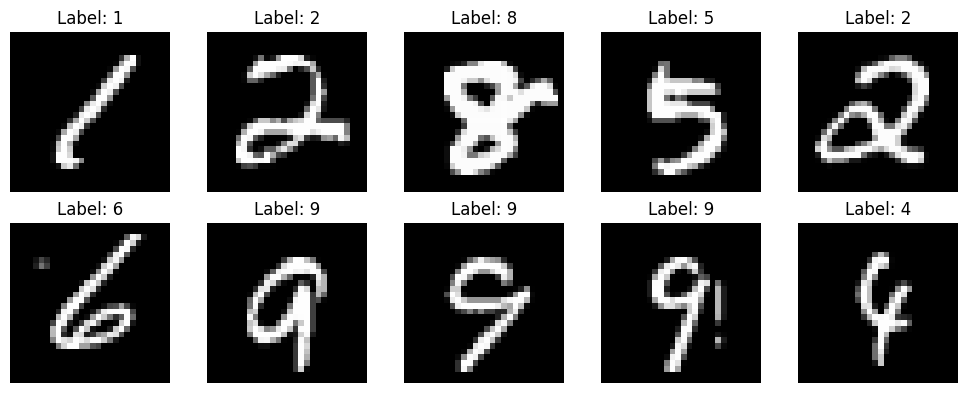

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    image = images[i].squeeze().cpu()
    image = (image + 1) / 2

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Part A: Forward Diffusion

The forward diffusion process gradually adds Gaussian noise to a clean image. A linear noise schedule is used with 100 diffusion steps, starting from beta = 0.0001 and ending at beta = 0.02.

In [5]:
T = 100

beta_start = 0.0001
beta_end = 0.02

betas = torch.linspace(beta_start, beta_end, T, device=device)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

print("Number of diffusion steps:", T)
print("Beta shape:", betas.shape)
print("First beta:", betas[0].item())
print("Last beta:", betas[-1].item())
print("First alpha_bar:", alpha_bars[0].item())
print("Last alpha_bar:", alpha_bars[-1].item())

Number of diffusion steps: 100
Beta shape: torch.Size([100])
First beta: 9.999999747378752e-05
Last beta: 0.019999999552965164
First alpha_bar: 0.9998999834060669
Last alpha_bar: 0.36356320977211


In [6]:
def forward_diffusion(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    alpha_bar_t = alpha_bars[t].view(-1, 1, 1, 1)

    xt = (
        torch.sqrt(alpha_bar_t) * x0
        + torch.sqrt(1.0 - alpha_bar_t) * noise
    )

    return xt, noise

In [7]:
test_images = images[:8].to(device)

test_t = torch.full(
    (test_images.size(0),),
    49,
    device=device,
    dtype=torch.long
)

noisy_images, sampled_noise = forward_diffusion(
    test_images,
    test_t
)

print("Original shape:", test_images.shape)
print("Noisy image shape:", noisy_images.shape)
print("Noise shape:", sampled_noise.shape)

print(
    "Contains NaN:",
    torch.isnan(noisy_images).any().item()
)

Original shape: torch.Size([8, 1, 28, 28])
Noisy image shape: torch.Size([8, 1, 28, 28])
Noise shape: torch.Size([8, 1, 28, 28])
Contains NaN: False


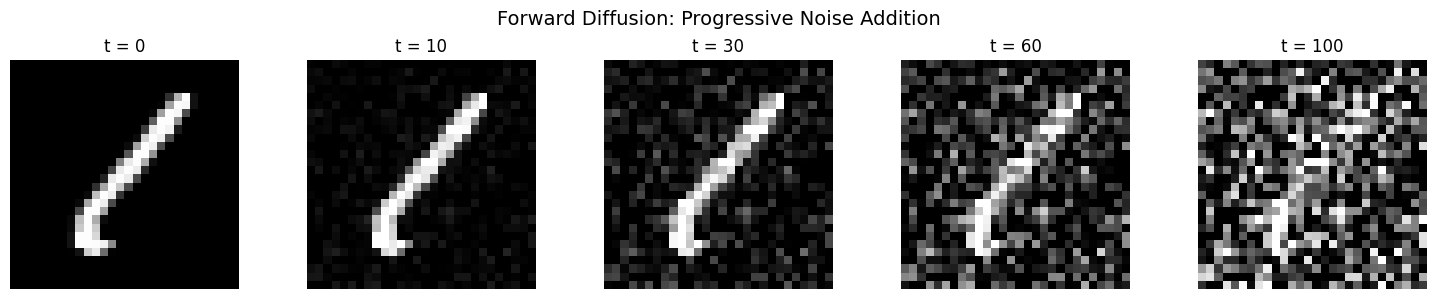

In [8]:
x0 = images[0:1].to(device)

display_steps = [0, 10, 30, 60, 100]

fixed_noise = torch.randn_like(x0)

fig, axes = plt.subplots(1, len(display_steps), figsize=(15, 3))

for ax, step in zip(axes, display_steps):

    if step == 0:
        xt = x0
    else:
        t_index = step - 1

        t = torch.tensor(
            [t_index],
            device=device,
            dtype=torch.long
        )

        xt, _ = forward_diffusion(
            x0,
            t,
            noise=fixed_noise
        )

    image_to_show = xt.squeeze().detach().cpu()
    image_to_show = (image_to_show + 1) / 2

    ax.imshow(
        image_to_show,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"t = {step}")
    ax.axis("off")

plt.suptitle(
    "Forward Diffusion: Progressive Noise Addition",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Forward Diffusion Observation

The visualization shows the gradual corruption of an MNIST image as the diffusion timestep increases. At early timesteps, the digit remains clearly recognizable because only a small amount of Gaussian noise has been added. As the timestep increases, the cumulative noise becomes stronger and the original image structure becomes progressively less visible. By the final timestep, noise dominates much of the image, demonstrating the forward diffusion process that the model will later learn to reverse.

## Part B: Mini DDPM Noise Prediction Network

The reverse diffusion model is trained to predict the Gaussian noise added to an MNIST image at a randomly selected diffusion timestep. The CNN is conditioned on the timestep so that it can learn how the amount of noise changes throughout the diffusion process.

In [9]:
class NoisePredictor(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()

        self.time_dim = time_dim

        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.ReLU(),
            nn.Linear(time_dim, time_dim),
            nn.ReLU()
        )

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(32, 1, kernel_size=3, padding=1)

        self.time_to_channels = nn.Linear(time_dim, 64)

    def forward(self, x, t):
        t = t.float().unsqueeze(1) / T

        time_embedding = self.time_mlp(t)
        time_embedding = self.time_to_channels(time_embedding)
        time_embedding = time_embedding[:, :, None, None]

        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))

        x = x + time_embedding

        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.conv5(x)

        return x


model = NoisePredictor().to(device)

print(model)

num_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"\nTrainable parameters: {num_parameters:,}")

NoisePredictor(
  (time_mlp): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv5): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_to_channels): Linear(in_features=64, out_features=64, bias=True)
)

Trainable parameters: 82,945


In [10]:
test_x = images[:8].to(device)

test_t = torch.randint(
    0,
    T,
    (test_x.size(0),),
    device=device
)

with torch.no_grad():
    test_output = model(test_x, test_t)

print("Input shape:", test_x.shape)
print("Timestep shape:", test_t.shape)
print("Output shape:", test_output.shape)

assert test_output.shape == test_x.shape

print("Shape check passed.")

Input shape: torch.Size([8, 1, 28, 28])
Timestep shape: torch.Size([8])
Output shape: torch.Size([8, 1, 28, 28])
Shape check passed.


In [11]:
criterion = nn.MSELoss()

sample_images = images[:8].to(device)

sample_t = torch.randint(
    0,
    T,
    (sample_images.size(0),),
    device=device,
    dtype=torch.long
)

noisy_sample, true_noise = forward_diffusion(
    sample_images,
    sample_t
)

predicted_noise = model(
    noisy_sample,
    sample_t
)

test_loss = criterion(
    predicted_noise,
    true_noise
)

print("Clean images:", sample_images.shape)
print("Noisy images:", noisy_sample.shape)
print("True noise:", true_noise.shape)
print("Predicted noise:", predicted_noise.shape)
print("Initial MSE loss:", test_loss.item())

assert torch.isfinite(test_loss)

print("Loss check passed.")

Clean images: torch.Size([8, 1, 28, 28])
Noisy images: torch.Size([8, 1, 28, 28])
True noise: torch.Size([8, 1, 28, 28])
Predicted noise: torch.Size([8, 1, 28, 28])
Initial MSE loss: 1.0126333236694336
Loss check passed.


### Training Configuration

The noise prediction network is trained by sampling a random diffusion timestep for each image, adding Gaussian noise using the forward diffusion process, and minimizing the mean squared error between the true noise and the predicted noise.

In [12]:
LEARNING_RATE = 1e-3
NUM_EPOCHS = 50

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.MSELoss()

training_losses = []
epoch_times = []

print("Training configuration")
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Optimizer: Adam")
print("Loss: MSE")
print("Device:", device)

Training configuration
Epochs: 50
Batch size: 128
Learning rate: 0.001
Optimizer: Adam
Loss: MSE
Device: cuda


In [13]:
training_start_time = time.time()

for epoch in range(NUM_EPOCHS):
    model.train()

    epoch_start_time = time.time()
    running_loss = 0.0

    for batch_images, _ in train_loader:
        batch_images = batch_images.to(device)

        batch_size = batch_images.size(0)

        t = torch.randint(
            0,
            T,
            (batch_size,),
            device=device,
            dtype=torch.long
        )

        noisy_images, true_noise = forward_diffusion(
            batch_images,
            t
        )

        predicted_noise = model(
            noisy_images,
            t
        )

        loss = criterion(
            predicted_noise,
            true_noise
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    epoch_time = time.time() - epoch_start_time

    training_losses.append(average_loss)
    epoch_times.append(epoch_time)

    print(
        f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | "
        f"Loss: {average_loss:.6f} | "
        f"Time: {epoch_time:.2f}s"
    )

total_training_time = time.time() - training_start_time

print()
print("Training complete")
print(f"Initial epoch loss: {training_losses[0]:.6f}")
print(f"Final epoch loss: {training_losses[-1]:.6f}")
print(f"Best epoch loss: {min(training_losses):.6f}")
print(f"Total training time: {total_training_time:.2f}s")

Epoch 01/50 | Loss: 0.156066 | Time: 13.10s
Epoch 02/50 | Loss: 0.087733 | Time: 12.56s
Epoch 03/50 | Loss: 0.080872 | Time: 13.01s
Epoch 04/50 | Loss: 0.076872 | Time: 12.72s
Epoch 05/50 | Loss: 0.076468 | Time: 12.56s
Epoch 06/50 | Loss: 0.073553 | Time: 12.62s
Epoch 07/50 | Loss: 0.073220 | Time: 12.75s
Epoch 08/50 | Loss: 0.071201 | Time: 12.63s
Epoch 09/50 | Loss: 0.070399 | Time: 12.88s
Epoch 10/50 | Loss: 0.070624 | Time: 12.63s
Epoch 11/50 | Loss: 0.069324 | Time: 12.99s
Epoch 12/50 | Loss: 0.069390 | Time: 12.66s
Epoch 13/50 | Loss: 0.068681 | Time: 12.70s
Epoch 14/50 | Loss: 0.068103 | Time: 12.69s
Epoch 15/50 | Loss: 0.068243 | Time: 12.52s
Epoch 16/50 | Loss: 0.067014 | Time: 12.65s
Epoch 17/50 | Loss: 0.066881 | Time: 12.77s
Epoch 18/50 | Loss: 0.066586 | Time: 12.69s
Epoch 19/50 | Loss: 0.066701 | Time: 12.40s
Epoch 20/50 | Loss: 0.066353 | Time: 12.42s
Epoch 21/50 | Loss: 0.065744 | Time: 12.75s
Epoch 22/50 | Loss: 0.065597 | Time: 12.60s
Epoch 23/50 | Loss: 0.066028 | T

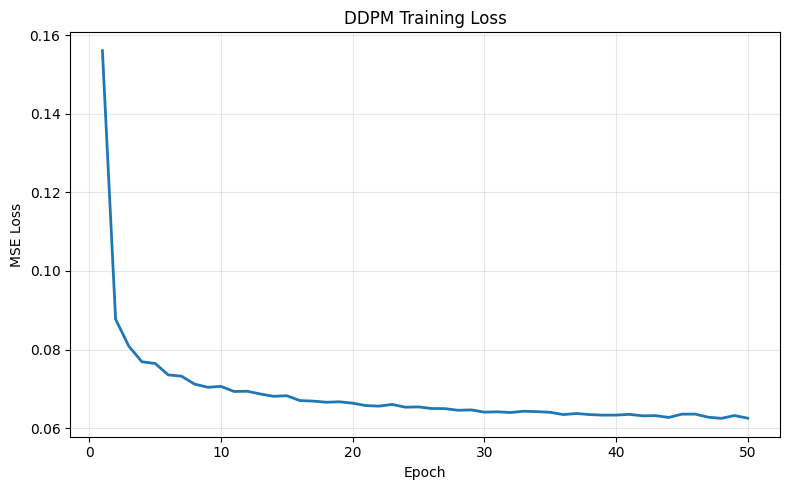

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    training_losses,
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("DDPM Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
best_epoch = int(np.argmin(training_losses)) + 1
best_loss = min(training_losses)

loss_reduction = (
    (training_losses[0] - training_losses[-1])
    / training_losses[0]
) * 100

average_epoch_time = np.mean(epoch_times)

print("DDPM Training Metrics")
print("=" * 30)
print(f"Initial loss: {training_losses[0]:.6f}")
print(f"Final loss: {training_losses[-1]:.6f}")
print(f"Best loss: {best_loss:.6f}")
print(f"Best epoch: {best_epoch}")
print(f"Loss reduction: {loss_reduction:.2f}%")
print(f"Average epoch time: {average_epoch_time:.2f} seconds")
print(f"Total training time: {total_training_time:.2f} seconds")

DDPM Training Metrics
Initial loss: 0.156066
Final loss: 0.062526
Best loss: 0.062490
Best epoch: 48
Loss reduction: 59.94%
Average epoch time: 12.71 seconds
Total training time: 635.28 seconds


In [16]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "training_losses": training_losses,
    "epoch_times": epoch_times,
    "num_epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "T": T,
    "beta_start": beta_start,
    "beta_end": beta_end
}

torch.save(
    checkpoint,
    "HW8_ddpm_checkpoint.pt"
)

print("Checkpoint saved successfully.")

Checkpoint saved successfully.
